# Questions
1) What does Engagement_Score look like overall? (average, minimum, maximum, spread, shape)
2) Do Avg_Session_Minutes and Titles_Watched affect Engagement_Score?
3) Does Engagement_Score differ by Subscription_Plan, Device, City or Preferred_Genre?
4) Which viewers need attention? (Engagement_Score below 45 = “At Risk”)


In [33]:
import pandas as pd

df = pd.read_csv("../data/raw/ott_data.csv")

print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

for col in ["City", "Subscription_Plan", "Device", "Preferred_Genre"]:
    print(df[col].value_counts())

  Viewer_ID       City Subscription_Plan    Device Preferred_Genre   Age  \
0     V1193      Delhi            Mobile    Mobile          Comedy  21.0   
1     V1173      Delhi            Mobile    Mobile           Drama  35.0   
2     V1221     Mumbai          Standard  Smart_TV           Drama  29.0   
3     V1208     Mumbai          Standard    Mobile     Documentary  38.0   
4     V1195  Bengaluru            Mobile    Laptop          Comedy  29.0   

   Avg_Session_Minutes  Titles_Watched  Buffering_Incidents Last_Active_Date  \
0                 47.0               6                    6       2026-09-16   
1                 48.0              11                    3       2025-06-09   
2                 25.0               9                    4       2026-01-04   
3                 54.0              10                    3       2025-02-23   
4                 71.0              12                    4       2025-07-03   

   Engagement_Score  
0              60.3  
1              42.

In [34]:
import pandas as pd

df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

df_clean["City"] = df_clean["City"].str.strip().str.title()

df_clean.loc[df_clean["Age"] < 16, "Age"] = df_clean["Age"].median()
df_clean.loc[df_clean["Age"] > 60, "Age"] = df_clean["Age"].median()

df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Avg_Session_Minutes"] = df_clean["Avg_Session_Minutes"].fillna(df_clean["Avg_Session_Minutes"].median())

df_clean["Device"] = df_clean["Device"].fillna(df_clean["Device"].mode()[0])
df_clean["Preferred_Genre"] = df_clean["Preferred_Genre"].fillna(df_clean["Preferred_Genre"].mode()[0])

print(df_clean.shape)
print(df_clean.isnull().sum())
print(df_clean.duplicated().sum())
print(df_clean["City"].value_counts())
print(df_clean.describe())

df_clean.to_csv("../data/processed/ott_data_clean.csv", index=False)

(250, 11)
Viewer_ID              0
City                   0
Subscription_Plan      0
Device                 0
Preferred_Genre        0
Age                    0
Avg_Session_Minutes    0
Titles_Watched         0
Buffering_Incidents    0
Last_Active_Date       0
Engagement_Score       0
dtype: int64
0
City
Delhi        70
Bengaluru    63
Mumbai       62
Pune         31
Lucknow      24
Name: count, dtype: int64
              Age  Avg_Session_Minutes  Titles_Watched  Buffering_Incidents  \
count  250.000000           250.000000      250.000000           250.000000   
mean    27.936000            47.888000        9.964000             3.020000   
std      7.431339            15.540963        2.978286             1.800156   
min     16.000000            10.000000        2.000000             0.000000   
25%     23.000000            39.000000        8.000000             2.000000   
50%     28.000000            47.000000       10.000000             3.000000   
75%     32.000000            58.0000

## What does Engagement_Score look like overall? (average, minimum, maximum, spread, shape)

count    250.000000
mean      58.234400
std       11.963469
min       30.700000
25%       50.100000
50%       58.250000
75%       66.175000
max       94.400000
Name: Engagement_Score, dtype: float64


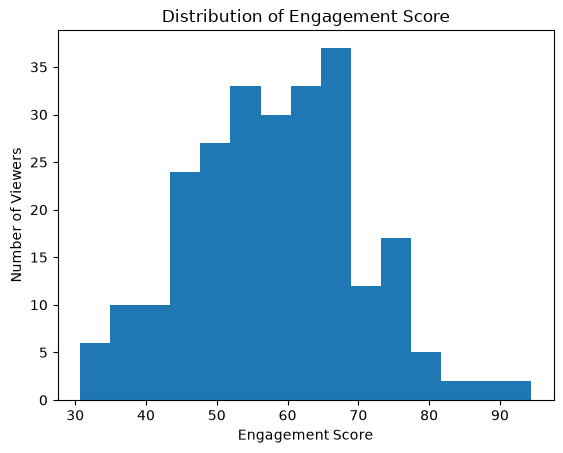

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df_clean["Engagement_Score"].describe())

plt.hist(df_clean["Engagement_Score"], bins=15)
plt.title("Distribution of Engagement Score")
plt.xlabel("Engagement Score")
plt.ylabel("Number of Viewers")
plt.savefig("../images/q1_score_distribution.png")
plt.show()

## Do Avg_Session_Minutes and Titles_Watched affect Engagement_Score?

                     Avg_Session_Minutes  Titles_Watched  Engagement_Score
Avg_Session_Minutes             1.000000        0.101691          0.536696
Titles_Watched                  0.101691        1.000000          0.562285
Engagement_Score                0.536696        0.562285          1.000000


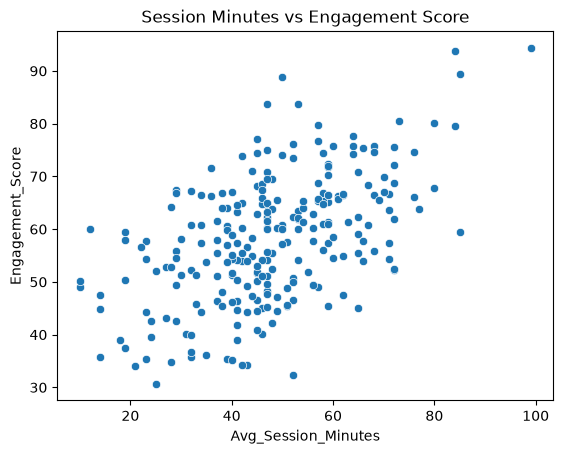

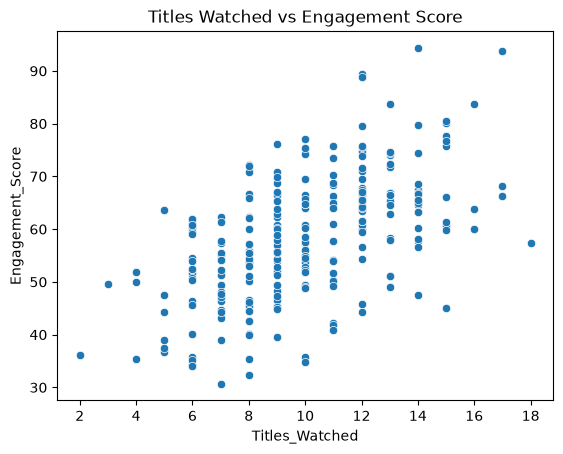

In [36]:
print(df_clean[["Avg_Session_Minutes", "Titles_Watched", "Engagement_Score"]].corr())

sns.scatterplot(x="Avg_Session_Minutes", y="Engagement_Score", data=df_clean)
plt.title("Session Minutes vs Engagement Score")
plt.savefig("../images/q2_session_vs_score.png")
plt.show()

sns.scatterplot(x="Titles_Watched", y="Engagement_Score", data=df_clean)
plt.title("Titles Watched vs Engagement Score")
plt.savefig("../images/q2_titles_vs_score.png")
plt.show()

## Does Engagement_Score differ by Subscription_Plan, Device, City or Preferred_Genre?

Subscription_Plan
Basic       58.0
Mobile      58.9
Premium     60.5
Standard    56.3
Name: Engagement_Score, dtype: float64

Device
Laptop      60.9
Mobile      55.8
Smart_TV    60.3
Tablet      59.1
Name: Engagement_Score, dtype: float64

City
Bengaluru    58.5
Delhi        58.3
Lucknow      58.5
Mumbai       58.4
Pune         57.2
Name: Engagement_Score, dtype: float64

Preferred_Genre
Action         57.9
Comedy         58.8
Documentary    57.8
Drama          59.7
Thriller       56.5
Name: Engagement_Score, dtype: float64



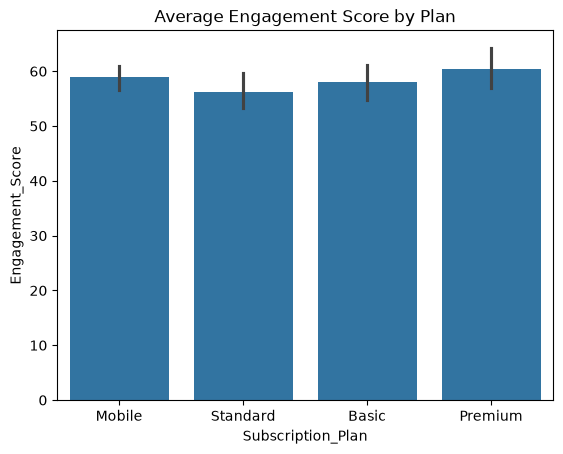

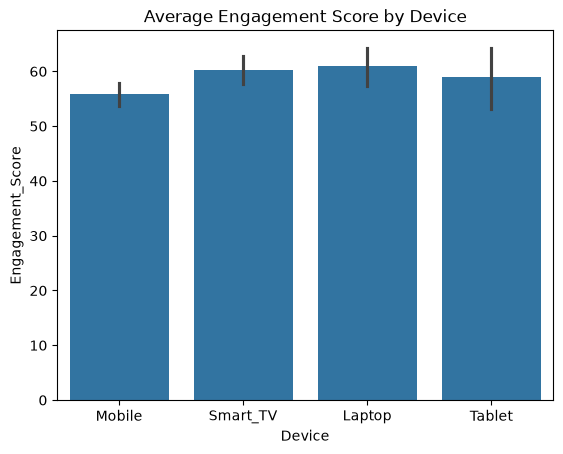

In [37]:
for col in ["Subscription_Plan", "Device", "City", "Preferred_Genre"]:
    print(df_clean.groupby(col)["Engagement_Score"].mean().round(1))
    print()

sns.barplot(x="Subscription_Plan", y="Engagement_Score", data=df_clean)
plt.title("Average Engagement Score by Plan")
plt.savefig("../images/q3_score_by_plan.png")
plt.show()

sns.barplot(x="Device", y="Engagement_Score", data=df_clean)
plt.title("Average Engagement Score by Device")
plt.savefig("../images/q3_score_by_device.png")
plt.show()

## Which viewers need attention? (Engagement_Score below 45 = “At Risk”)

At_Risk
False    217
True      33
Name: count, dtype: int64
Subscription_Plan
Basic       10
Mobile       6
Premium      4
Standard    13
Name: At_Risk, dtype: int64
Device
Laptop       1
Mobile      22
Smart_TV     7
Tablet       3
Name: At_Risk, dtype: int64


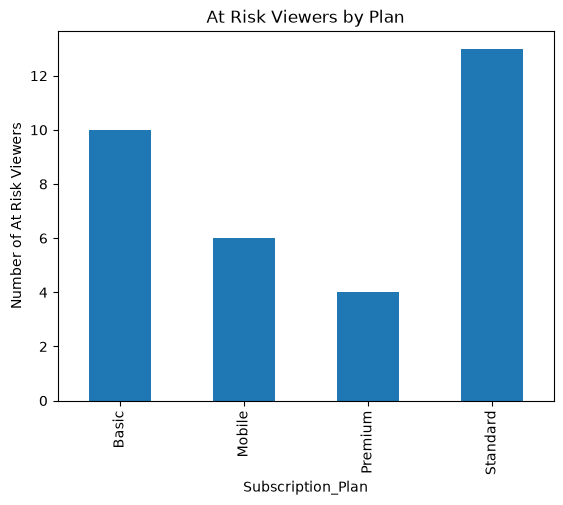

In [38]:
df_clean["At_Risk"] = df_clean["Engagement_Score"] < 45

print(df_clean["At_Risk"].value_counts())
print(df_clean.groupby("Subscription_Plan")["At_Risk"].sum())
print(df_clean.groupby("Device")["At_Risk"].sum())

df_clean.groupby("Subscription_Plan")["At_Risk"].sum().plot(kind="bar")
plt.title("At Risk Viewers by Plan")
plt.ylabel("Number of At Risk Viewers")
plt.savefig("../images/q4_at_risk_by_plan.png")
plt.show()